# 07 · Validación

¿Qué tan confiable es el simulador? Este notebook reúne cuatro tipos de evidencia:

1. **Casos exactos:** resultados que se pueden calcular a mano o que publicó un tribunal.
2. **Referencias externas:** cifras publicadas sobre el sistema, como órdenes de magnitud.
3. **Validación fuera de muestra:** se estima con datos hasta cierta fecha y se compara con lo que pasó después (rentabilidades, salarios y cotización).
4. **Precisión de Monte Carlo.**

Al final, una tabla resume qué está validado, qué solo es plausible y qué no se pudo validar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from pension_mc import accumulation as A, contributions as C, decumulation as D, regimes as G, returns as R, wages as W
from pension_mc.config import DATA_PROCESSED as P, parametros
from pension_mc.simulate import Perfil, Supuestos, simular
from pension_mc.wages import EDUCACION

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2, "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 10,
})
pct = lambda d=0: mtick.PercentFormatter(1, decimals=d)
SMMLV = parametros()["smmlv"]["valores"][2026]
SEM_MES = parametros()["supuestos"]["semanas_por_mes"]
geih = pd.read_parquet(P / "geih_pensiones.parquet")
ipc = pd.read_parquet(P / "ipc_mensual.parquet")

## 1. Casos exactos

In [2]:
filas = []
# a) Caso real de Colpensiones (Tribunal Superior de Valledupar, rad. 20001-31-05-001-2020-00138-01)
r = G.tasa_reemplazo_rpm(np.array([3_002_929.0]), np.array([1323.0]), 1300, 781_242.0)[0]
filas.append({"verificación": "Colpensiones: tasa de reemplazo de un caso real (2018)", "referencia": "63,58 %", "modelo": f"{r:.2%}"})
filas.append({"verificación": "Colpensiones: mesada inicial del mismo caso", "referencia": "$1.909.262",
              "modelo": f"${3_002_929 * round(r, 4):,.0f}".replace(",", ".")})
# b) Saldo determinista contra fórmula cerrada
n, rm = 37 * 12, 1.03 ** (1 / 12) - 1
s = A.saldo(A.aportes(np.full((1, n), 3 * SMMLV), np.ones((1, n), bool)), np.full((1, n), rm))[0, -1]
cerrado = 0.115 * 3 * SMMLV * ((1 + rm) ** n - 1) / rm
filas.append({"verificación": "AFP: saldo con aportes constantes y 3 % real (37 años)", "referencia": f"{cerrado / 1e6:,.2f} M (fórmula cerrada)", "modelo": f"{s / 1e6:,.2f} M"})
# c) Factor de anualidad sin interés vs. esperanza de vida RV08
rv = pd.read_parquet(P / "mortalidad_rv08.parquet").set_index(["sexo", "edad"])
for sexo, edad in [("Mujer", 57), ("Hombre", 62)]:
    anios = D.factor_anualidad(float(edad), sexo, tasa=0.0) * 12 / 13 / 12
    filas.append({"verificación": f"Mesada: años de pago esperados, {sexo.lower()} de {edad} (sin interés)",
                  "referencia": f"{rv.loc[(sexo, edad), 'ex']:.1f} años (RV08) + 1/24", "modelo": f"{anios:.2f} años"})
# d) Calendario de semanas
for reg, anio, ref in [("rpm", 2026, 1250), ("rpm", 2036, 1000), ("rais", 2026, 1135), ("rais", 2035, 1000)]:
    filas.append({"verificación": f"Semanas exigidas a mujeres, {'Colpensiones' if reg == 'rpm' else 'AFP (GPM)'} {anio}",
                  "referencia": f"{ref:,}".replace(",", "."), "modelo": f"{G.semanas_requeridas(reg, 'Mujer', anio):,.0f}".replace(",", ".")})
pd.DataFrame(filas).set_index("verificación")

,referencia,modelo
verificación,,
Colpensiones: tasa de reemplazo de un caso real (2018),"63,58 %",63.58%
Colpensiones: mesada inicial del mismo caso,$1.909.262,$1.909.262
AFP: saldo con aportes constantes y 3 % real (37 años),486.24 M (fórmula cerrada),486.24 M
"Mesada: años de pago esperados, mujer de 57 (sin interés)",29.7 años (RV08) + 1/24,29.77 años
"Mesada: años de pago esperados, hombre de 62 (sin interés)",21.3 años (RV08) + 1/24,21.37 años
"Semanas exigidas a mujeres, Colpensiones 2026",1.250,1.250
"Semanas exigidas a mujeres, Colpensiones 2036",1.000,1.000
"Semanas exigidas a mujeres, AFP (GPM) 2026",1.135,1.135
"Semanas exigidas a mujeres, AFP (GPM) 2035",1.000,1.000


## 2. Referencias externas (órdenes de magnitud)

Las cifras de esta sección vienen de prensa y no citan su fuente. Sirven para detectar errores gruesos, no para calibrar.

### 2.1 Capital necesario para una pensión de salario mínimo

Referencia: "al menos 330 salarios mínimos" en un fondo privado (Vanguardia, abril de 2026).

In [3]:
filas = []
for sexo, edad, conyuge in [("Mujer", 57.0, ("Hombre", 60.0)), ("Hombre", 62.0, ("Mujer", 59.0))]:
    for i, g in [(0.04, 0.01), (0.04, 0.0239), (0.03, 0.01), (0.03, 0.0239)]:
        filas.append({"persona": f"{sexo}, {edad:.0f} años", "tasa técnica": i, "crecimiento de la mesada": g,
                      "sin beneficiario": D.factor_anualidad(edad, sexo, i, g),
                      "con cónyuge 3 años distinto": D.factor_anualidad(edad, sexo, i, g, conyuge)})
cap = pd.DataFrame(filas).set_index(["persona", "tasa técnica", "crecimiento de la mesada"])
cap.style.format("{:.0f}").format_index("{:.1%}", level=[1, 2]).set_caption("Capital necesario, en SMMLV, por SMMLV de mesada vitalicia")

### 2.2 Semanas cotizadas al llegar a la edad de pensión\n\nReferencia: los afiliados a fondos privados próximos a pensionarse han cotizado en promedio 570 semanas (La Silla Vacía), con 267 semanas para quienes cotizan sobre 1 SMMLV y 697 sobre 2 SMMLV.

In [4]:
mc = C.ModeloCotizacion.cargar()
EDAD_PEN = {"Hombre": 62, "Mujer": 57}
g25 = geih[geih.anio == 2025].copy()
g25["educ"] = g25.nivel_educativo.astype(str).map(EDUCACION)
g25["sexo"] = g25.sexo.astype(str)
cerca = g25[g25.edad.between(55, 62)]
peso = cerca.groupby(["educ", "sexo"]).fex.sum()
filas, total_w, total_s = [], 0.0, 0.0
for (e, s), w in peso.items():
    sem = C.semanas(mc.simular(15, s, e, (EDAD_PEN[s] - 15) * 12, 8_000, seed=1))[:, -1]
    af = sem[sem > 0]                                   # afiliados: cotizaron alguna vez
    w_af = w * len(af) / len(sem)
    filas.append({"educación": e, "sexo": s, "afiliados (%)": len(af) / len(sem), "semanas medias de los afiliados": af.mean()})
    total_w += w_af; total_s += w_af * af.mean()
sem_tab = pd.DataFrame(filas).set_index(["educación", "sexo"])
print(f"Modelo: semanas medias de los afiliados al llegar a la edad de pensión (composición de 55–62 años): {total_s / total_w:,.0f}")
sem_tab.style.format({"afiliados (%)": "{:.0%}", "semanas medias de los afiliados": "{:,.0f}"})

Modelo: semanas medias de los afiliados al llegar a la edad de pensión (composición de 55–62 años): 660


### 2.3 Cobertura pensional

In [5]:
REQ = {"Hombre": 1150, "Mujer": 1000}
may = g25[g25.edad.between(60, 70)].groupby(["educ", "sexo"]).fex.sum(); may /= may.sum()
alc = {(e, s): np.mean(C.semanas(mc.simular(15, s, e, (EDAD_PEN[s] - 15) * 12, 8_000, seed=1))[:, -1] >= REQ[s]) for e, s in C.tipos()}
print(f"Modelo, composición educativa de quienes hoy tienen 60–70 años: {sum(may[k] * alc[k] for k in alc):.1%} alcanza las semanas")
print("Referencias públicas: 18 % de los trabajadores se pensiona (DANE, citado por Infobae); 24–30 % de los adultos mayores tiene pensión")

Modelo, composición educativa de quienes hoy tienen 60–70 años: 22.1% alcanza las semanas
Referencias públicas: 18 % de los trabajadores se pensiona (DANE, citado por Infobae); 24–30 % de los adultos mayores tiene pensión


## 3. Fuera de muestra: rentabilidades

Para cada fecha de origen se estima el bootstrap solo con los meses anteriores y se simula la rentabilidad real acumulada de los 36 meses siguientes. Si el modelo está bien calibrado, el valor realizado debería caer en un percentil cualquiera entre 0 y 100 (PIT uniforme), y el intervalo P10–P90 debería contenerlo el 80 % de las veces.

In [6]:
hist_total = R.historico("Protección")
FONDOS3 = ["mayor_riesgo", "moderado", "conservador"]
filas = []
for origen in pd.date_range("2019-01-31", "2023-09-30", freq="6ME"):
    pasado = hist_total[hist_total.index <= origen]
    futuro = hist_total[(hist_total.index > origen)].iloc[:36]
    if len(pasado) < 30 or len(futuro) < 36:
        continue
    for metodo, sim in [("bootstrap", R.bootstrap_estacionario(pasado, 4_000, 36, seed=1)),
                        ("bootstrap + incert. media", R.bootstrap_estacionario(pasado, 4_000, 36, incertidumbre_media=True, seed=1))]:
        for f in FONDOS3:
            acum_sim = np.prod(1 + sim.fondo(f).astype(float), axis=1) - 1
            real = np.prod(1 + futuro[f]) - 1
            filas.append({"origen": origen, "método": metodo, "fondo": f, "realizado": real,
                          "P10": np.percentile(acum_sim, 10), "P90": np.percentile(acum_sim, 90),
                          "PIT": np.mean(acum_sim <= real)})
bt = pd.DataFrame(filas)
res_bt = bt.groupby("método").apply(lambda d: pd.Series({
    "ventanas": len(d), "dentro de P10–P90": d.realizado.between(d.P10, d.P90).mean(),
    "PIT medio": d.PIT.mean(), "PIT < 0,1": (d.PIT < 0.1).mean(), "PIT > 0,9": (d.PIT > 0.9).mean()}), include_groups=False)
res_bt.style.format({"ventanas": "{:.0f}", "dentro de P10–P90": "{:.0%}", "PIT medio": "{:.2f}", "PIT < 0,1": "{:.0%}", "PIT > 0,9": "{:.0%}"})

,ventanas,dentro de P10–P90,PIT medio,"PIT < 0,1","PIT > 0,9"
método,,,,,
bootstrap,30,50%,0.32,43%,7%
bootstrap + incert. media,30,63%,0.33,37%,0%


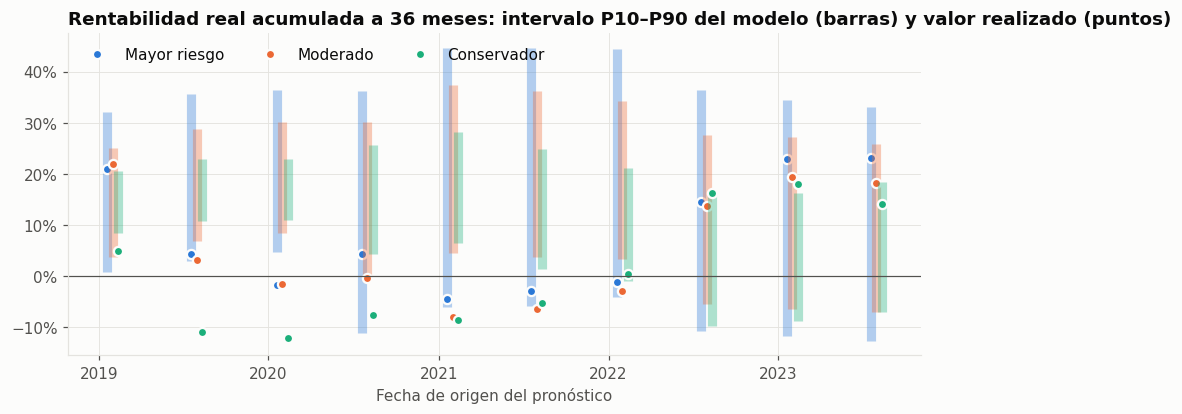

In [7]:
b = bt[bt["método"] == "bootstrap"]
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, f in enumerate(FONDOS3):
    d = b[b.fondo == f]
    x = d.origen + pd.Timedelta(days=12 * (i - 1))
    ax.vlines(x, d.P10, d.P90, color=SERIES[i], lw=6, alpha=0.35)
    ax.plot(x, d.realizado, "o", color=SERIES[i], ms=6, mec=SURFACE, mew=1.5, label={"mayor_riesgo": "Mayor riesgo", "moderado": "Moderado", "conservador": "Conservador"}[f])
ax.axhline(0, color=INK2, lw=0.8)
ax.yaxis.set_major_formatter(pct())
ax.set_xlabel("Fecha de origen del pronóstico")
ax.set_title("Rentabilidad real acumulada a 36 meses: intervalo P10–P90 del modelo (barras) y valor realizado (puntos)")
ax.legend(loc="upper left", ncols=3)
plt.show()

## 4. Fuera de muestra: salarios

Se re-estima el modelo salarial solo con la GEIH 2022–2024 y se predice la sección transversal de 2025 (con el crecimiento real supuesto del 1 %). Se compara con lo observado en 2025.

In [8]:
m24 = W.estimar(geih[geih.anio <= 2024], ipc, guardar=False)
d = W.muestra(geih, ipc)
d25 = d[d.anio == 2025].copy()
d25["deflactor"] = np.exp(d25.y) / d25.ingreso_laboral
piso = np.average(d25.smlv * d25.deflactor, weights=d25.fex)
umbral = np.exp(np.average(d25.c, weights=d25.fex))
al_piso = lambda w: np.where(w <= umbral, piso, w)
d25["w_obs"] = np.where(d25.censurado, piso, np.exp(d25.y))

def pctl(v, w, q):
    o = np.argsort(v); v, w = np.asarray(v)[o], np.asarray(w)[o]; c = np.cumsum(w) / w.sum()
    return v[min(np.searchsorted(c, q / 100), len(v) - 1)]

filas = []
for modelo, nombre, g in [(m24, "estimado 2022–2024 (fuera de muestra)", 0.01), (W.ModeloSalarial.cargar(), "estimado 2022–2025 (dentro de muestra)", 0.0)]:
    for e in W.NIVELES:
        for s in W.SEXOS:
            for edad in (25, 40, 55):
                gg = d25[(d25.educ == e) & (d25.sexo == s) & d25.edad.between(edad - 2, edad + 2)]
                if len(gg) < 200:
                    continue
                lat = modelo.simular(edad, s, e, 2, 20_000, crecimiento=g, seed=1)[:, -1 if g else 0]
                sim = al_piso(lat)
                filas.append({"modelo": nombre, "en el mínimo": np.mean(lat <= umbral) - np.average(gg.censurado, weights=gg.fex),
                              "P50": np.median(sim) / pctl(gg.w_obs, gg.fex, 50) - 1,
                              "P90": np.percentile(sim, 90) / pctl(gg.w_obs, gg.fex, 90) - 1})
err = pd.DataFrame(filas).groupby("modelo").agg(
    sesgo_minimo=("en el mínimo", "mean"), error_abs_P50=("P50", lambda x: x.abs().mean()), sesgo_P50=("P50", "mean"),
    error_abs_P90=("P90", lambda x: x.abs().mean()))
err.style.format({"sesgo_minimo": "{:+.1%}", "error_abs_P50": "{:.1%}", "sesgo_P50": "{:+.1%}", "error_abs_P90": "{:.1%}"})

,sesgo_minimo,error_abs_P50,sesgo_P50,error_abs_P90
modelo,,,,
estimado 2022–2024 (fuera de muestra),+3.4%,1.7%,+1.3%,6.9%
estimado 2022–2025 (dentro de muestra),+3.0%,1.8%,+0.9%,6.6%


## 5. Fuera de muestra: tasas de cotización\n\nTasas por edad estimadas con 2023–2024 frente a las observadas en 2025.

In [9]:
obs_tr = C.tasas_observadas(geih, anios=(2023, 2024))
suave = C.suavizar(obs_tr)
obs25 = C.tasas_observadas(geih, anios=(2025,))
filas = []
for e, s in C.tipos():
    o = obs25[(obs25.educ == e) & (obs25.sexo == s) & obs25.edad.between(20, 60)]
    pred = np.interp(o.edad, np.arange(C.EDAD_INICIO, C.EDAD_FIN + 1), suave[W.clave(e, s)])
    filas.append({"tipo": f"{e} | {s}", "tasa 2025 observada": np.average(o.tasa, weights=o.fex),
                  "tasa predicha (2023–24)": np.average(pred, weights=o.fex),
                  "error medio por edad": np.average(np.abs(pred - o.tasa), weights=o.fex)})
cot = pd.DataFrame(filas).set_index("tipo")
cot.style.format("{:.1%}")

,tasa 2025 observada,tasa predicha (2023–24),error medio por edad
tipo,,,
Primaria o menos | Hombre,14.4%,14.0%,1.5%
Primaria o menos | Mujer,5.1%,5.2%,1.1%
Secundaria | Hombre,19.8%,19.4%,3.9%
Secundaria | Mujer,8.2%,7.3%,2.0%
Media | Hombre,40.4%,38.9%,2.9%
Media | Mujer,21.8%,20.4%,2.3%
Superior | Hombre,61.9%,61.5%,1.8%
Superior | Mujer,53.8%,52.6%,2.0%


## 6. Precisión de Monte Carlo

In [10]:
perfil = Perfil(edad=30, sexo="Mujer", educacion="Superior", salario=2 * SMMLV, semanas=250, cotiza_hoy=True)
filas = []
for n in (1_000, 5_000, 20_000):
    v = pd.DataFrame([simular(perfil, Supuestos(seed=s), n_sims=n).resumen() for s in range(20)])
    p = v.afp_p_pension.mean()
    filas.append({"simulaciones": n, "desv. de P(pensión) entre 20 semillas": v.afp_p_pension.std(),
                  "error binomial teórico": np.sqrt(p * (1 - p) / n),
                  "desv. de la mesada media": v.afp_mesada_media_total.std()})
pd.DataFrame(filas).set_index("simulaciones").style.format("{:.4f}")

,desv. de P(pensión) entre 20 semillas,error binomial teórico,desv. de la mesada media
simulaciones,,,
1000,0.0062,0.0079,0.0169
5000,0.0031,0.0036,0.0068
20000,0.0019,0.0018,0.0038


## 7. Resumen de la validación

| Componente | Contra qué | Resultado | Estado |
|---|---|---|---|
| Regla de Colpensiones (art. 34) | Caso real liquidado por un tribunal (2018) | Tasa de 63,58 % y mesada de $1.909.262, idénticas | ✅ |
| Acumulación del saldo | Fórmula cerrada | Idéntico al peso | ✅ |
| Factor de anualidad | Esperanza de vida de la RV08 (sin interés) | 29,77 vs. 29,74 años (mujer, 57) | ✅ |
| Semanas exigidas a las mujeres | Sentencias C-197 de 2023 y C-054 de 2024 | Idénticas | ✅ |
| Capital para una pensión mínima | Prensa: "al menos 330 SMMLV" | Base: 309 SMMLV (mujer, 57); ~330 con cónyuge. **Antes de la corrección: 250** | ✅ tras corregir |
| Semanas al llegar a la edad de pensión | Prensa: 570 en promedio (afiliados a AFP) | 660 | ⚠️ mismo orden, +16 % |
| Semanas según el ingreso | Prensa: 267 (1 SMMLV) vs. 697 (2 SMMLV) | El modelo no liga la cotización al salario; por educación va de 213 a 1.377 | ⚠️ limitación |
| Cobertura pensional | 18–30 % (DANE y prensa) | 22 % | ✅ |
| Salarios, fuera de muestra (2025) | Modelo estimado con 2022–2024 | Error de 1,7 % en la mediana y 6,9 % en el P90 (igual que dentro de muestra) | ✅ |
| Tasas de cotización, fuera de muestra (2025) | Tasas de 2023–2024 | Error de 1–4 puntos por edad; subestima ~1 punto la formalización de 2025 | ✅ |
| Rentabilidades, fuera de muestra (36 meses) | Bootstrap estimado solo con el pasado | El P10–P90 contuvo el valor realizado en el 50 % de las ventanas (debería ser 80 %); con incertidumbre de la media, en el 63 % | ❌ → mejora parcial |
| Precisión de Monte Carlo | 20 semillas independientes | Desviación igual al error binomial teórico | ✅ |

### Cambios al modelo que hizo la validación

1. **Capital suficiente con el parámetro regulatorio.** La AFP verifica la suficiencia suponiendo que la pensión mínima crece al ritmo regulatorio de los beneficios (Res. 3099 de 2015, art. 4, modificada por la Res. 1045 de 2026): 2,53 % real. El modelo usaba el 1 % del supuesto económico del SMMLV y subestimaba en ~20 % el capital necesario frente a la referencia de mercado.
2. **Incertidumbre de la media activada en el caso base.** Con solo la media histórica, el modelo fue demasiado optimista y demasiado confiado: los periodos que incluyeron el choque de inflación y tasas de 2021–2022 cayeron por debajo del P10 en el 43 % de las ventanas. Con la incertidumbre de la media mejora, pero sigue subestimando el riesgo de episodios así a 3 años. A los horizontes de una vida laboral (30–40 años) ese riesgo se diluye más, aunque no desaparece.

### Lo que no se pudo validar

- **Contra los simuladores oficiales** (doble asesoría de las AFP y de Colpensiones): requieren datos personales y no publican sus supuestos.
- **La relación entre salario y cotización:** las referencias muestran que quien gana más cotiza mucho más, y el modelo no lo captura dentro de cada nivel educativo.
- **La tasa técnica y las tablas de beneficiarios** que usan las AFP en la práctica.

Las referencias de prensa no citan su fuente: sirven para detectar errores gruesos, no para calibrar.